# Проект спринта 24. Подготовка витрин данных для рекомендательной системы

## Цель проекта
Необходимо построить ETL-пайплайн, который будет собирать пять витрин данных разной степени детализации для рекомендательной системы. Количество витрин обусловлено тем, что для выдачи корректных рекомендаций нужны данные на разных уровнях абстракции. 

| **Витрина**       | **Решаемая задача**                                                                                                                                                                                                                             |
| ----------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| user_content_mart | • Обучение моделей рекомендаций разных типов (ranking, implicit feedback) на основе того, что пользователь уже читал или слушал.  <br>• Расчёт признаков, основанных на взаимодействии пользователя с разными произведениями.                   |
| user_genre_mart   | • Построение профиля интересов пользователя.  <br>• Рекомендации при «холодном старте» пользователя (англ. cold start scenario), то есть при отсутствии значительной истории данных.  <br>• Генерация рекомендаций по жанрам.                   |
| user_mart         | • Хранение пользовательских фич, то есть определение профиля пользователя.  <br>• Сегментация пользователей.                                                                                                                                    |
| content_mart      | • Хранение контентных фич, то есть данных о популярности и качестве контента.  <br>• Оценка популярности конкретных произведений.  <br>• Создание сбалансированных и персонализированных рекомендаций, а не просто сводки популярного контента. |
| daily_user_mart   | • Определение динамики активности пользователей.  <br>• Хранение признаков, основанных на временных паттернах.                                                                                                                                  |

## Описание исходных данных

Исходные данные — представлены таблицами в формате Parquet. Таблица `audition.parquet` хранит данные об активности пользователей и содержит такие поля:

- `audition_id` — уникальный идентификатор сессии чтения или прослушивания.
- `puid` — идентификатор пользователя.
- `usage_platform_ru` — название платформы, с помощью которой пользователь слушал контент.
- `msk_business_dt_str` — дата события в формате строки (московское время).
- `app_version` — версия приложения, которая использовалась для чтения или прослушивания.
- `adult_content_flg` — метка контента для пользователей старше 18 лет, `True` или `False`.
- `hours` — длительность чтения или прослушивания за сессию в часах.
- `hours_sessions_long` — продолжительность длинных сессий чтения или прослушивания в часах.
- `kids_content_flg` — метка детского контента, `True` или `False`.
- `main_content_id` — идентификатор произведения (книги, аудиокниги или другой контент).
- `usage_geo_id` — идентификатор географического местоположения пользователя.

Таблица `content.parquet` хранит данные о контенте и содержит такие поля:

- `main_content_id` — идентификатор основного контента.
- `main_author_id` — идентификатор основного автора контента.
- `main_content_type` — тип контента.
- `main_content_name` — название контента.
- `main_content_duration_hours` — длительность контента в часах.
- `published_topic_title_list` — список жанров контента.

## Описание витрин
### Витрина `user_content_mart`

Витрина должна содержать следующие поля:

1. `puid` — идентификатор пользователя.
2. `main_content_id` — идентификатор произведения.
3. `total_hours` — суммарное время, проведённое за чтением и прослушиванием контента в часах.
4. `sessions_count` — количество сессий чтения и прослушивания.
5. `finished_percent` — сколько процентов произведения пользователь прочёл или прослушал.
6. `is_completed` — метка, показывающая, завершил ли пользователь чтение или прослушивание книги. `1` присваивается, если процент завершённости больше или равен 1, где 1 — это 100% произведения.
7. `last_listening_date` — дата последней сессии чтения или прослушивания.
8. `days_spent` — количество дней, проведённых за прослушиванием и прочтением. Необходимо считать количество уникальных активных дней: Последнийдень−Первыйдень+1.Последнийдень−Первыйдень+1.
9. `avg_session_hours` — среднее время сессии прослушивания или чтения в часах.

### Витрина `user_genre_mart`

Витрина должна содержать следующие поля:

1. `puid` — идентификатор пользователя.
2. `genre` — жанр произведения.
3. `total_hours` — сколько времени в часах пользователь провёл с произведениями данного жанра.
4. `sessions_count` — количество сессий, проведённых за чтением или прослушиванием произведений этого жанра.
5. `completed_count` — количество завершённых произведений в жанре.
6. `genre_rank` — ранг жанра среди всех остальных у пользователя.
7. `adult_count` — количество произведений в определённом жанре с рейтингом 18+, которые прочёл или прослушал пользователь.
8. `kids_count` — количество детских произведений в определённом жанре, которые прочёл или прослушал пользователь.

### Витрина `user_mart`

Витрина должна содержать следующие поля:

1. `puid` — идентификатор пользователя.
2. `total_hours` — суммарное время, проведённое за чтением и прослушиванием контента в часах.
3. `active_days` — количество дней, проведённых за чтением или прослушиванием.
4. `unique_content_count` — количество произведений, прочитанных и прослушанных пользователем.
5. `unique_genres_count` — количество жанров, книги в которых читал или слушал пользователь.
6. `completion_rate` — средний уровень завершённости произведений.
7. `favorite_genre` — любимый жанр пользователя.
8. `favorite_content_type` — любимый тип контента пользователя.
9. `favourite_platform` — любимая платформа пользователя.
10. `last_date` — дата последнего прослушивания или прочтения.
11. `adult_content_count` — количество произведений для лиц старше 18 лет, прослушанных и прочтённых пользователем.
12. `kids_content_count` — количество детских произведений, прослушанных и прочтённых пользователем.

### Витрина `content_mart`

Витрина должна содержать следующие поля:

1. `main_content_id` — уникальный идентификатор контента.
2. `unique_users` — количество уникальных пользователей сервиса.
3. `total_hours` — общее количество часов, потраченных пользователями на определённое произведение.
4. `avg_finished_percent` — средний процент завершённости. Чтобы получить этот показатель, нужно сначала вычислить `user_total_hours` — количество часов, которое пользователи провели за единицей контента. Для расчёта нужно использовать исходные данные — а именно содержимое колонки `hours`. После этого надо рассчитать процент завершённости произведения для каждого пользователя (`user_total_hours / main_content_duration_hours`). После этого можно получить среднюю долю завершённости по контенту. Результат можно умножить на 100, чтобы перейти от долей к процентам.
5. `platforms_count` — количество платформ, на которых доступно произведение.
6. `popularity` — популярность произведения, то есть количество пользователей, взаимодействовавших с ним, делённое на общее количество пользователей.

### Витрина daily_user_mart

Витрина должна содержать следующие поля:

1. `puid` — уникальный идентификатор пользователя.
2. `session_date` — дата.
3. `day_of_week` — день недели.
4. `content_count` — количество произведений, которые пользователь читал или слушал за день.
5. `hours_spent` — количество часов, проведённых за разным контентом в определённую дату.
6. `sessions_count` — количество сессий за день.

## 1. Установка и импорт библиотек

In [1]:
%pip install pyspark dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


- Импорт необходимых библиотек

In [ ]:
import os
from dotenv import load_dotenv

from pyspark.sql import SparkSession
from pyspark.sql import functions as F, Window

# Для форматирования в HTML
from IPython.display import display, HTML, Markdown

from sprint24_utils import create_spark_session_dict
import plot_utils as pu

Note: you may need to restart the kernel to use updated packages.


- Определим константы

In [3]:
AUDITION_FILE_NAME = 'audition.parquet'
CONTENT_FILE_NAME = 'content.parquet'

## 2. Загрузка и первоначальное знакомство с данными

- Создание сессии Spark

In [4]:

load_dotenv()
s3_common_bucket = os.getenv("S3_COMMON_BUCKET")
s3_bucket = os.getenv("S3_BUCKET")

# Workaround for Windows
os.environ["HADOOP_HOME"] = os.getcwd() + "\\Hadoop\\"

spark = create_spark_session_dict(appName="Sprint_24_jpynb",
                                 master="local[*]",
                                 conf_dict={
                                    "spark.executor.memory": "2g",
                                    "spark.executor.cores": "2",
                                    "spark.executor.instances": "2",
                                    "spark.driver.cores": "4",
                                    "spark.driver.memory": "8g",
                                    "spark.sql.shuffle.partitions": "32",
                                    "spark.network.timeout": "300",
                                    "spark.jars.packages": "org.apache.spark:spark-hadoop-cloud_2.13:3.5.0,software.amazon.awssdk:bundle:2.35.4",
                                    "spark.hadoop.fs.s3a.access.key": os.getenv("S3_ACCESS_KEY"),
                                    "spark.hadoop.fs.s3a.secret.key": os.getenv("S3_SECRET_KEY"),
                                    "spark.hadoop.fs.s3a.endpoint": os.getenv("S3_ENDPOINT"),
                                    "spark.hadoop.fs.s3a.impl": "org.apache.hadoop.fs.s3a.S3AFileSystem",
                                    "spark.hadoop.fs.s3a.aws.credentials.provider": "org.apache.hadoop.fs.s3a.SimpleAWSCredentialsProvider",
                                    "spark.hadoop.fs.s3a.path.style.access": "true",

                                    # Замена несовместимых значений параметров по умолчанию
                                    "spark.hadoop.fs.s3a.threads.keepalivetime": "60000",
                                    "spark.hadoop.fs.s3a.connection.establish.timeout": "30000",
                                    "spark.hadoop.fs.s3a.retry.interval": "500",
                                    "spark.hadoop.fs.s3a.retry.throttle.interval": "100",
                                    "spark.hadoop.fs.s3a.connection.timeout": "200",
                                    "spark.hadoop.fs.s3a.multipart.purge.age": "86400000"
                                    })


c:\Users\TEXNH MAKPH\Projects\Yandex DS\ds-yandex\.venv312\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


- Загружаем файлы

In [5]:
df_audition = spark.read.parquet(f"s3a://{s3_common_bucket}/{AUDITION_FILE_NAME}")
df_content = spark.read.parquet(f"s3a://{s3_common_bucket}/{CONTENT_FILE_NAME}")

# Для отладки. TODO: удалить после отладки
df_audition.cache()
df_content.cache()

DataFrame[main_content_id: string, main_content_type: string, main_content_name: string, main_content_duration_hours: double, published_topic_title_list: string, main_author_id: string]

- Выведем информацию о датасетах

In [6]:
display(HTML(f"""<h2>Audition DataFrame</h2>
<h3>Количество строк: {df_audition.count()}</h3>
<h3>Количество столбцов: {len(df_audition.columns)}</h3>"""))

df_audition.show(5)
df_audition.printSchema()

display(HTML(f"""<h2>Content DataFrame</h2>
<h3>Количество строк: {df_content.count()}</h3>
<h3>Количество столбцов: {len(df_content.columns)}</h3>"""))

df_content.show(5)
df_content.printSchema()

+-----------+--------------------+-----------------+-------------------+-----------+-----------------+------------------+-------------------+----------------+---------------+--------------------+-----------------+
|audition_id|                puid|usage_platform_ru|msk_business_dt_str|app_version|adult_content_flg|             hours|hours_sessions_long|kids_content_flg|main_content_id|        usage_geo_id|__index_level_0__|
+-----------+--------------------+-----------------+-------------------+-----------+-----------------+------------------+-------------------+----------------+---------------+--------------------+-----------------+
|          0|68296628-f9d6-11e...|          Станция|         2024-11-26|       NULL|            false|0.0377777777777777| 0.0377777777777777|            true|       oCURrBKV|   Алматы, Казахстан|              162|
|          1|682966dc-f9d6-11e...|          Станция|         2024-11-26|       NULL|            false| 8.333333333333E-4|                0.0|   

+---------------+-----------------+--------------------+---------------------------+--------------------------+--------------------+
|main_content_id|main_content_type|   main_content_name|main_content_duration_hours|published_topic_title_list|      main_author_id|
+---------------+-----------------+--------------------+---------------------------+--------------------------+--------------------+
|       A00hxVIL|             Book|Давай поговорим о...|                      4.151|      'Синхронизировано...|        Карл Ричардс|
|       A03if3j5|        Comicbook|Минимализм из ком...|                  2.6854546|      'Уборка и организ...|Элизабет Энрайт Ф...|
|       A05XPJgr|             Book| Гоните ваши денежки|                  6.9114366|      'Художественная л...|Наталья Александрова|
|       A06fBP22|             Book|Крайон. Судьбу мо...|                  3.5218182|      'Эзотерика', 'Окк...|        Тамара Шмидт|
|       A0FkgwIl|        Comicbook|Майор Гром. Допол...|             

- В датасете `auditions` 1002896 строк, 12 столбцов. Все столбцы могут содержать пустые значения. Типы данных столбцов соответствуют содержащимся в них данных, за исключением столбца `msk_business_dt_str`, содержащего дату в строковом формате. Этот столбец должен быть приведен к типу `date`.
- В датасете `content` 31668 строк, 6 столбцов. Все столбцы могут содержать пустые значения. Типы данных столбцов соответствуют содержащимся в них данных.

## 3. Преобразование и исследовательский анализ данных
### 3.1. Обработка пропусков и аномальных значений

- Добавим столбец типа `date` для даты, содержащейся в `msk_business_dt_str`

In [7]:
df_audition = df_audition.withColumn('msk_business_dt', F.to_date(F.col('msk_business_dt_str'), 'yyyy-MM-dd'))

- Выведем статистики для числовых столбцов

In [8]:
df_audition.describe('hours', 'hours_sessions_long').show()
pc_grades = [0.25, 0.5, 0.75, 0.90, 0.98, 0.99]
display(HTML("<h3>Процентильные значения для столбца hours</h3>"))
hours_perc = df_audition.approxQuantile('hours', pc_grades, 0.01)
display(list(zip(pc_grades, hours_perc)))
display(HTML("<h3>Процентильные значения для столбца hours_sessions_long</h3>"))
hours_sessions_long_perc = df_audition.approxQuantile('hours_sessions_long', pc_grades, 0.01)
display(list(zip(pc_grades, hours_sessions_long_perc)))

df_content.describe('main_content_duration_hours').show()
display(HTML("<h3>Процентильные значения для столбца main_content_duration_hours</h3>"))
main_content_duration_hours_perc = df_content.approxQuantile('main_content_duration_hours', pc_grades, 0.01)
display(list(zip(pc_grades, main_content_duration_hours_perc)))

+-------+------------------+-------------------+
|summary|             hours|hours_sessions_long|
+-------+------------------+-------------------+
|  count|           1002896|            1002896|
|   mean|0.4194248205040685|0.41561910149156744|
| stddev|1.1615985389812162| 1.1601987892447272|
|    min|    2.777777777E-7|                0.0|
|    max|321.26334545454546| 321.24690909090907|
+-------+------------------+-------------------+



[(0.25, 0.0405555555555555),
 (0.5, 0.1247222222222222),
 (0.75, 0.23),
 (0.9, 0.9513888888888888),
 (0.98, 3.90072),
 (0.99, 321.26334545454546)]

[(0.25, 0.0430555555555555),
 (0.5, 0.1261111111111111),
 (0.75, 0.2262909090909091),
 (0.9, 0.9198727272727272),
 (0.98, 3.791944444444444),
 (0.99, 321.24690909090907)]

+-------+---------------------------+
|summary|main_content_duration_hours|
+-------+---------------------------+
|  count|                      31662|
|   mean|          8.315491295691517|
| stddev|          7.966225047175883|
|    min|                        0.0|
|    max|                  293.75012|
+-------+---------------------------+



[(0.25, 3.745278),
 (0.5, 7.4680557),
 (0.75, 10.747128),
 (0.9, 14.7949095),
 (0.98, 22.746944),
 (0.99, 293.75012)]

- В числовых столбцах присутствуют выбросы - сессии аномальной длины (321 час).
- Есть контент с нулевой продолжительностью. Эти данные могут искажать статистику по прослушиваниям, поэтому их надо удалить.
- Также продолжительность контента 293 и более часов является аномальной (ориентировочно 9000 страниц текста и более).
- Можно отфильтровать датасеты по значению 98 процентиля числовых столбцов.

In [23]:
df_audition = df_audition.filter((F.col('hours') > 0) &
                                 (F.col('hours') <= hours_perc[-2]))
df_content = df_content.filter((F.col('main_content_duration_hours') > 0) &
                               (F.col('main_content_duration_hours') <= main_content_duration_hours_perc[-2]))

display(HTML(f"<h3>Количество строк df_audition после фильтрации: {df_audition.count()}</h3>"))
display(HTML(f"<h3>Количество строк df_content после фильтрации: {df_content.count()}</h3>"))

- Определим количество пропусков в датасетах

In [24]:
def count_nulls(df):
    null_counts = df.select([
        F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df.columns
    ])
    return null_counts

audition_null_counts = count_nulls(df_audition)
audition_null_counts.show()

content_null_counts = count_nulls(df_content)
content_null_counts.show()
df_audition.groupby('app_version').agg(F.count('*').alias('count')).orderBy('count', ascending=False).show(10)

+-----------+----+-----------------+-------------------+-----------+-----------------+-----+-------------------+----------------+---------------+------------+-----------------+---------------+
|audition_id|puid|usage_platform_ru|msk_business_dt_str|app_version|adult_content_flg|hours|hours_sessions_long|kids_content_flg|main_content_id|usage_geo_id|__index_level_0__|msk_business_dt|
+-----------+----+-----------------+-------------------+-----------+-----------------+-----+-------------------+----------------+---------------+------------+-----------------+---------------+
|          0|   0|                0|                  0|          0|                0|    0|                  0|               0|              0|           0|                0|              0|
+-----------+----+-----------------+-------------------+-----------+-----------------+-----+-------------------+----------------+---------------+------------+-----------------+---------------+

+---------------+-----------------

- Пропуски присутствуют только в столбце `app_version`. Заполним их нулями (индикатор пропуска).

In [11]:
df_audition = df_audition.fillna({'app_version': '0'})

- Объединим таблицы по полю `main_content_id`

In [12]:
df_joined = df_audition.join(df_content, on='main_content_id', how='left')
display(HTML(f"<h3>Количество строк df_joined после объединения: {df_joined.count()}</h3>"))


- Количество строк после объединения совпадает с количеством строк в `df_audition` - дубликатов не появилось.

- Отфильтруем данные по интервалу дат и местоположению и создадим списки по значениям `published_topic_title_list` 

In [13]:
def filter_data(df, start_date, end_date, usage_geo_id):
    return df.filter((F.col('msk_business_dt') >= start_date) &
                     (F.col('msk_business_dt') <= end_date) &
                     (F.col('usage_geo_id') == usage_geo_id))

def split_published_topics(df):
    return (df.withColumn('published_topic_title', F.explode(F.split(F.col('published_topic_title_list'), ',\\s*'))))

# df_joined_filtered = filter_data(df_joined, '2023-01-01', '2023-12-31', 1)
df_joined_filtered_split = split_published_topics(df_joined)

### 3.2. Исследовательский анализ данных

- Исследуем распределение пользователей по платформам.

c:\Users\TEXNH MAKPH\Projects\Yandex DS\ds-yandex\.venv312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\TEXNH MAKPH\Projects\Yandex DS\ds-yandex\.venv312\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


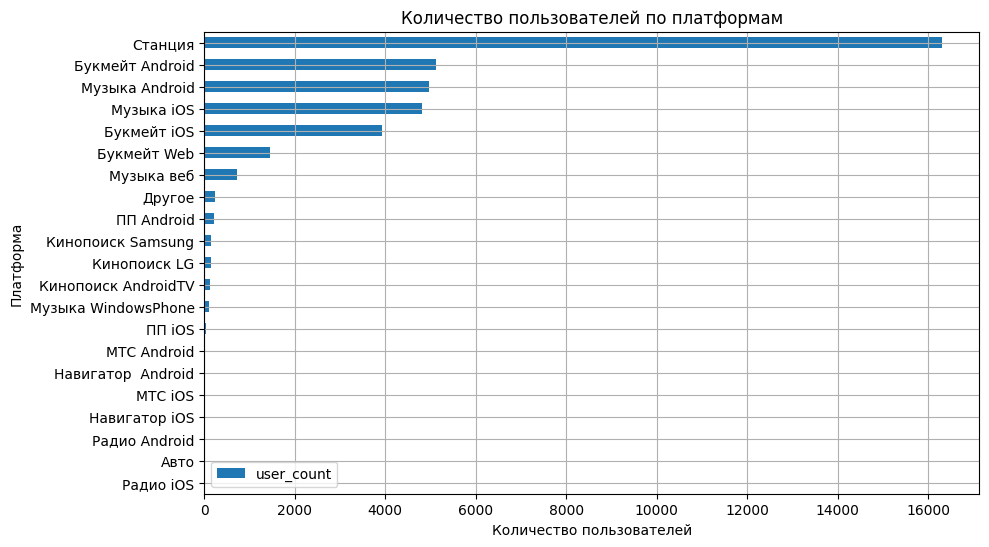

c:\Users\TEXNH MAKPH\Projects\Yandex DS\ds-yandex\.venv312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\TEXNH MAKPH\Projects\Yandex DS\ds-yandex\.venv312\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


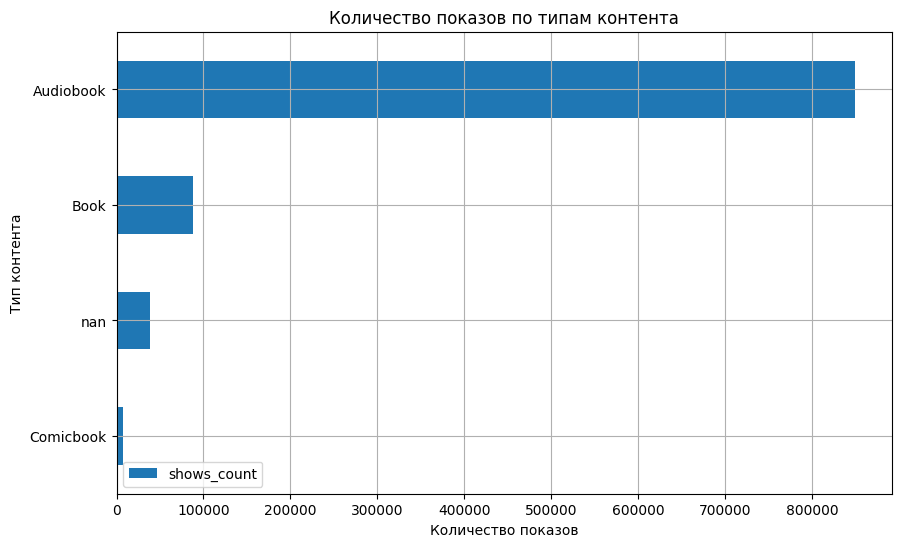

c:\Users\TEXNH MAKPH\Projects\Yandex DS\ds-yandex\.venv312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\TEXNH MAKPH\Projects\Yandex DS\ds-yandex\.venv312\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


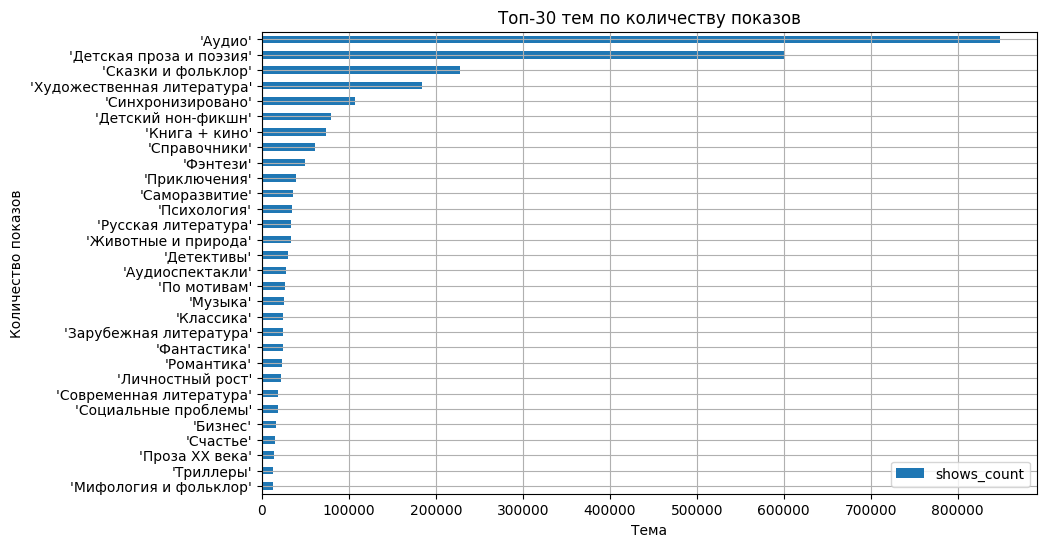

c:\Users\TEXNH MAKPH\Projects\Yandex DS\ds-yandex\.venv312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\TEXNH MAKPH\Projects\Yandex DS\ds-yandex\.venv312\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


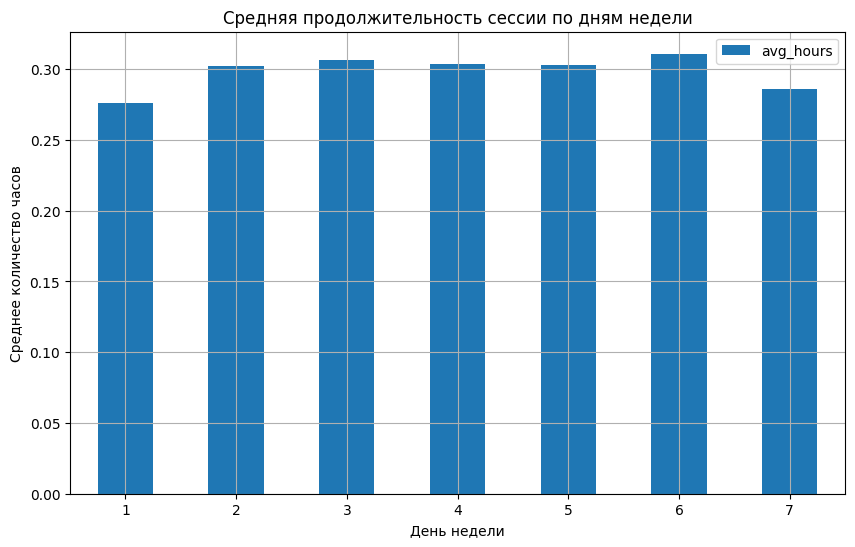

c:\Users\TEXNH MAKPH\Projects\Yandex DS\ds-yandex\.venv312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\TEXNH MAKPH\Projects\Yandex DS\ds-yandex\.venv312\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


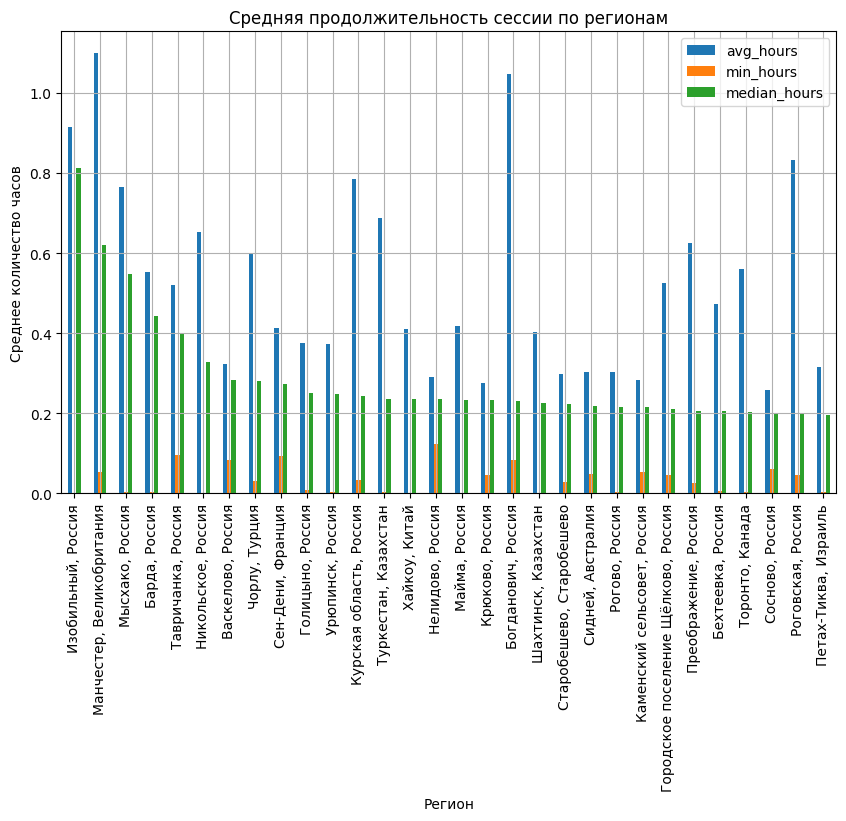

c:\Users\TEXNH MAKPH\Projects\Yandex DS\ds-yandex\.venv312\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\TEXNH MAKPH\Projects\Yandex DS\ds-yandex\.venv312\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


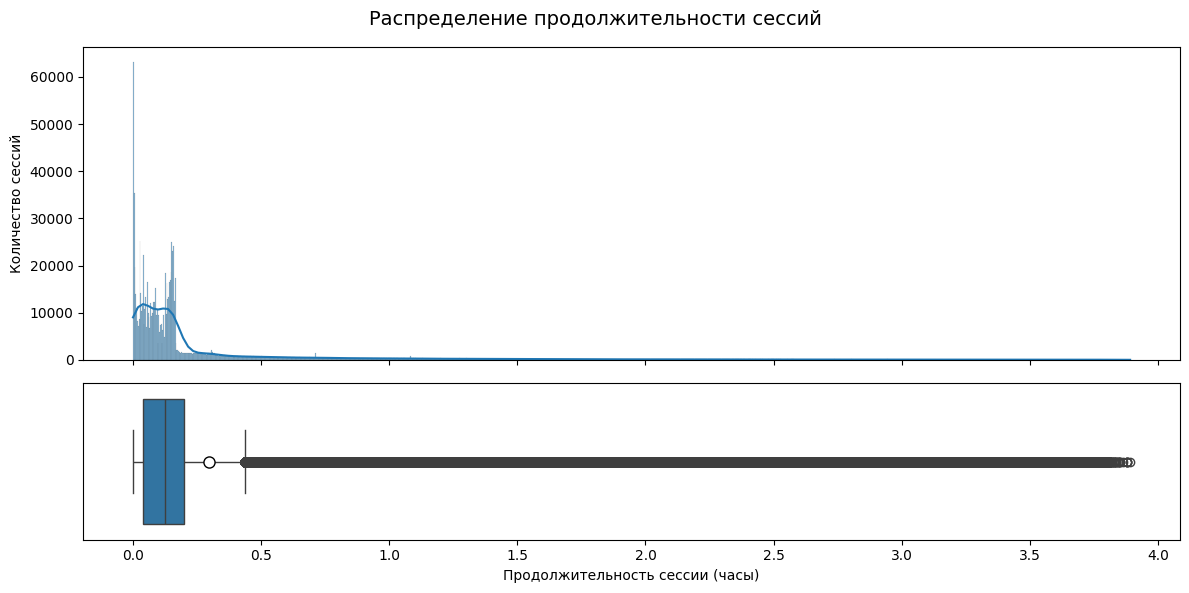

In [14]:
df_users_by_platform = (df_joined
                        .groupBy('usage_platform_ru')
                        .agg(F.countDistinct('puid').alias('user_count'))
                        .orderBy('user_count'))

df_shows_by_content_type = (df_joined
                        .groupBy('main_content_type')
                        .agg(F.count('puid').alias('shows_count'))
                        .orderBy('shows_count'))

df_shows_by_topic = (df_joined_filtered_split
                        .groupBy('published_topic_title')
                        .agg(F.count('puid').alias('shows_count'))
                        .orderBy('shows_count', ascending=False))

df_hours_by_dow = (df_joined
                   .select('msk_business_dt', 'hours')
                   .groupBy(F.dayofweek('msk_business_dt').alias('day_of_week'))
                   .agg(F.mean('hours').alias('avg_hours'))
                   .orderBy('day_of_week'))

df_hours_by_geo_id = (df_joined
                   .select('usage_geo_id', 'hours')
                   .groupBy('usage_geo_id')
                   .agg(F.mean('hours').alias('avg_hours'),
                        F.min('hours').alias('min_hours'),
                        F.median('hours').alias('median_hours'),
                        F.count('hours').alias('count_hours'))
                   .where(F.col('count_hours') > 5)
                   .drop('count_hours'))

pu.draw_barplot(df_users_by_platform.toPandas().set_index('usage_platform_ru'), 
                title='Количество пользователей по платформам', 
                xlabel='Платформа', 
                ylabel='Количество пользователей',
                figsize=(10, 6),
                vertical=False)

pu.draw_barplot(df_shows_by_content_type.toPandas().set_index('main_content_type'), 
                title='Количество показов по типам контента', 
                xlabel='Тип контента', 
                ylabel='Количество показов', 
                figsize=(10, 6),
                vertical=False)

pu.draw_barplot(df_shows_by_topic
                .toPandas()
                .head(30)
                .set_index('published_topic_title')
                .sort_values(by='shows_count'), 
                title='Топ-30 тем по количеству показов', 
                xlabel='Количество показов', 
                ylabel='Тема', 
                figsize=(10, 6),
                vertical=False)

pu.draw_barplot(df_hours_by_dow.toPandas().set_index('day_of_week'), 
                title='Средняя продолжительность сессии по дням недели', 
                xlabel='День недели', 
                ylabel='Среднее количество часов', 
                figsize=(10, 6))

pu.draw_barplot(df_hours_by_geo_id
                .toPandas()
                .sort_values(by='median_hours', ascending=False)
                .head(30)
                .set_index('usage_geo_id'),
                title='Средняя продолжительность сессии по регионам',
                xlabel='Регион',
                ylabel='Среднее количество часов',
                figsize=(10, 6),
                vertical=True,
                rot=90)

pu.draw_double_diag(df_audition
                    .toPandas(),
                    "Распределение продолжительности сессий",
                    'hours',
                    "Продолжительность сессии (часы)",
                    "Количество сессий")


- Наибольшей популярностью пользуются аудиокниги. Также есть категория `nan`, возникшая, вероятно, в результате ошибки при сборе данных или как заглушка для заполнения пропусков на этапе их подготовки.
- Наиболее популярные платформы - Станция, приложения Букмейт и Музыка на Android и Apple iOS.
- Среди жанров лидирует детская литература и художественная литература в целом. Название жанра "Синхронизировано", по всей видимости, ошибочно.
- Средняя продолжительность сессий больше по рабочим дням, в субботу и воскресенье она сокращается.
- Диаграмма зависимости продолжительности сессий от географического положения построена только для геометок с количеством сессий больше пяти. Зависимости продолжительности сессий от региона по диаграммам распределения не прослеживается.
- Продолжительность основного количества сессий - менее 15 минут. После этого значения количество сессий резко снижается, сессии длиной более получаса не попадают в межквартильный интервал и помечаются как выбросы.

## 4. Построение витрин данных
### 4.1. Витрина `user_content_mart`
- **NB:** Произведение считается прослушанным полностью, если суммарная продолжительность сессий, относящихся к данному произведению, больше его продолжительности.

In [15]:
user_content_mart_full = (df_joined
                     .groupBy('puid', 'main_content_id', 
                              'adult_content_flg', 
                              'kids_content_flg', 'main_content_type',
                              'main_content_duration_hours')
                     .agg(
                         F.sum('hours').alias('total_hours'),
                         F.count('audition_id').alias('sessions_count'),
                         F.min('msk_business_dt').alias('first_listening_date'),
                         F.max('msk_business_dt').alias('last_listening_date'),
                         F.mean('hours').alias('avg_session_hours')
                         )
                     .withColumn('finished_percent',
                                 F.when(F.col('main_content_duration_hours') == 0, 100)
                                 .otherwise(F.col('total_hours') / F.col('main_content_duration_hours') * 100))
                     .withColumn('is_completed', F.col('finished_percent') >= 100)
                     .withColumn('days_spent', F.datediff(F.col('last_listening_date'), F.col('first_listening_date')) + 1))

user_content_mart = (user_content_mart_full
                     .drop('first_listening_date', 'main_content_duration_hours', 
                           'adult_content_flg', 'kids_content_flg', 'main_content_type'))

user_content_mart.show(5)
user_content_mart.printSchema()

+--------------------+---------------+-------------------+--------------+-------------------+-------------------+------------------+------------+----------+
|                puid|main_content_id|        total_hours|sessions_count|last_listening_date|  avg_session_hours|  finished_percent|is_completed|days_spent|
+--------------------+---------------+-------------------+--------------+-------------------+-------------------+------------------+------------+----------+
|68296628-f9d6-11e...|       oCURrBKV|0.45388888888888856|             5|         2024-11-26|0.09077777777777771|54.667111283583466|       false|        32|
|6829677c-f9d6-11e...|       xnwMA9a7|              8.353|            13|         2024-12-10| 0.6425384615384615| 79.52112157816059|       false|        69|
|682968a8-f9d6-11e...|       lyfcbOOG|  2.050833333333333|            10|         2024-12-09|0.20508333333333328| 50.08479655221877|       false|        41|
|68296a38-f9d6-11e...|       Jsb5YDXS| 0.0216666666666666|

### 4.2. Витрина `user_genre_mart`

- **NB:** Ранг жанра для пользователя определяется в порядке приоритета:
    - суммарной продолжительностью прослушивания;
    - количеством сессий с произведениями этого жанра.

In [16]:
user_genre_content_mart = (df_joined_filtered_split
                   .groupBy('puid', 
                            'published_topic_title', 
                            'main_content_id', 
                            'main_content_duration_hours', 
                            'adult_content_flg', 
                            'kids_content_flg')
                   .agg(
                       F.sum('hours').alias('total_hours_cont'),
                       F.count('audition_id').alias('sessions_count_cont')
                       ))

# Логика поиска любимого жанра, платформы, типа контента
favourites_window = (Window.partitionBy('puid')
                          .orderBy(F.col('total_hours').desc(),
                                   F.col('sessions_count').desc()))

user_genre_mart = (user_genre_content_mart
                   .groupBy('puid', 'published_topic_title')
                   .agg(
                       F.sum('total_hours_cont').alias('total_hours'),
                       F.sum('sessions_count_cont').alias('sessions_count'),
                       F.count_if(F.col('adult_content_flg')).alias('adult_count'),
                       F.count_if(F.col('kids_content_flg')).alias('kids_count'),
                       F.count_if(F.col('total_hours_cont') >= F.col('main_content_duration_hours'))
                       .alias('completed_count')
                       )
                    .withColumnRenamed('published_topic_title', 'genre')
                    .withColumn('genre_rank', 
                                F.row_number()
                                .over(favourites_window)))

user_genre_mart.show(5)      
user_genre_mart.printSchema()          

+--------------------+--------------------+------------------+--------------+-----------+----------+---------------+----------+
|                puid|               genre|       total_hours|sessions_count|adult_count|kids_count|completed_count|genre_rank|
+--------------------+--------------------+------------------+--------------+-----------+----------+---------------+----------+
|682966dc-f9d6-11e...|             'Аудио'|23.114166666666655|           254|          7|        87|             15|         1|
|682966dc-f9d6-11e...|'Детская проза и ...| 21.70749999999999|           228|          6|        78|             15|         2|
|682966dc-f9d6-11e...| 'Сказки и фольклор'| 8.138055555555551|            85|          2|        46|             11|         3|
|682966dc-f9d6-11e...|  'Синхронизировано'|1.7994444444444437|            10|          1|         8|              2|         4|
|682966dc-f9d6-11e...|    'Аудиоспектакли'|1.4574999999999987|            25|          0|         1|    

### 4.3. Витрина `user_mart`

In [17]:
# Агрегация по жанру
user_genre_agg = (user_genre_mart
                  .withColumn('favourite_genre',
                               F.first('genre').over(Window.partitionBy('puid').orderBy('genre_rank')))
                  .groupBy('puid', 'favourite_genre')
                  .agg(F.count('genre').alias('unique_genres_count')))

# Агрегация по платформе
user_platform_agg = (df_audition
                     .groupBy('puid', 'usage_platform_ru')
                     .agg(
                        F.count('audition_id').alias('sessions_count'),
                        F.sum('hours').alias('total_hours')
                        )
                     .withColumn('rank', F.row_number().over(favourites_window))
                     .filter(F.col('rank') == 1)
                     .select('puid', F.col('usage_platform_ru').alias('favourite_platform')))

# Итоговая витрина
user_mart = (user_content_mart_full
             .join(user_genre_agg, on='puid', how='inner')
             .join(user_platform_agg, on='puid', how='inner')
             .withColumn('favorite_content_type', F.first('main_content_type').over(favourites_window))
             .groupBy('puid', 'unique_genres_count', 'favourite_genre', 'favorite_content_type', 'favourite_platform')
             .agg(
                 F.sum('total_hours').alias('total_hours'),
                 F.count('main_content_id').alias('unique_content_count'),
                 F.min('first_listening_date').alias('first_listening_date'),
                 F.max('last_listening_date').alias('last_date'),
                 (100 * F.mean(F.col('is_completed').cast('int'))).alias('completion_rate'),
                 F.count_if('adult_content_flg').alias('adult_content_count'),
                 F.count_if('kids_content_flg').alias('kids_content_count')
                 )
             .withColumn('active_days', F.datediff(F.col('last_date'), F.col('first_listening_date')) + 1)
             .drop('first_listening_date', 'last_listening_date'))

user_mart.show(5)
user_mart.printSchema()

+--------------------+-------------------+---------------+---------------------+------------------+------------------+--------------------+----------+------------------+-------------------+------------------+-----------+
|                puid|unique_genres_count|favourite_genre|favorite_content_type|favourite_platform|       total_hours|unique_content_count| last_date|   completion_rate|adult_content_count|kids_content_count|active_days|
+--------------------+-------------------+---------------+---------------------+------------------+------------------+--------------------+----------+------------------+-------------------+------------------+-----------+
|68296704-f9d6-11e...|                  8|        'Спорт'|                 Book|       Букмейт iOS|0.0669292929292928|                   3|2024-11-26|               0.0|                  3|                 0|         37|
|682968c6-f9d6-11e...|                 34|        'Аудио'|            Audiobook|           Станция| 34.0547500000004

### 4.4. Витрина `content_mart`

In [18]:
# Агрегация по платформе
content_platform_agg = (df_audition
                     .groupBy('main_content_id')
                     .agg(F.countDistinct('usage_platform_ru').alias('platforms_count')))

content_mart = (user_content_mart_full
                .groupBy('main_content_id', 'main_content_duration_hours')
                .agg(
                    F.count('puid').alias('unique_users'),
                    F.sum('total_hours').alias('total_hours'),
                    F.mean(F.when(F.col('main_content_duration_hours') == 0, 100)
                            .otherwise(100 * F.col('total_hours') / F.col('main_content_duration_hours')))
                     .alias('avg_finished_percent')
                     )
                .join(content_platform_agg, on='main_content_id', how='inner')
                .join(df_audition.agg(F.countDistinct('puid').alias('total_users')), how='cross')
                .withColumn('popularity', F.col('unique_users') / F.col('total_users'))
                .drop('total_users', 'main_content_duration_hours'))

content_mart.show(5)
content_mart.printSchema()

+---------------+------------+------------------+--------------------+---------------+--------------------+
|main_content_id|unique_users|       total_hours|avg_finished_percent|platforms_count|          popularity|
+---------------+------------+------------------+--------------------+---------------+--------------------+
|       Un8UckXi|        2256| 1147.491665833346|   72.09069726535333|              5| 0.07271320827692902|
|       PZuYe128|          63|118.03252727272726|  29.594604307304632|              3|0.002030555018371688|
|       dResJCEX|          45|107.59931609611446|   51.34167448367211|              6|0.001450396441694...|
|       hUUAapl5|        1406|301.75522608918453|  248.43432836034063|              5| 0.04531683104493006|
|       xgsrBNWT|         584|125.32931000000076|   9.903575420446337|              2|0.018822922709985174|
+---------------+------------+------------------+--------------------+---------------+--------------------+
only showing top 5 rows
root

### 4.5. Витрина `daily_user_mart`

In [19]:
daily_user_mart = (df_audition
                   .groupBy('puid', F.col('msk_business_dt').alias('session_date'))
                   .agg(
                       F.countDistinct('main_content_id').alias('content_count'),
                       F.sum('hours').alias('hours_spent'),
                       F.countDistinct('audition_id').alias('sessions_count')
                   )
                   .withColumn('day_of_week', F.dayofweek('session_date')))

daily_user_mart.show(5)
daily_user_mart.printSchema()

+--------------------+------------+-------------+------------------+--------------+-----------+
|                puid|session_date|content_count|       hours_spent|sessions_count|day_of_week|
+--------------------+------------+-------------+------------------+--------------+-----------+
|68296fa6-f9d6-11e...|  2024-11-26|            1|1.0596458333333334|             1|          3|
|68297190-f9d6-11e...|  2024-11-26|           10|1.2074999999999996|            10|          3|
|68297aa0-f9d6-11e...|  2024-11-13|            6|0.5538888888888885|             6|          4|
|68299440-f9d6-11e...|  2024-11-26|            2|0.4947797979797979|             2|          3|
|68299d28-f9d6-11e...|  2024-11-26|            5|0.4427777777777775|             5|          3|
+--------------------+------------+-------------+------------------+--------------+-----------+
only showing top 5 rows
root
 |-- puid: string (nullable = true)
 |-- session_date: date (nullable = true)
 |-- content_count: long (nul

## 5. Анализ плана выполнения `user_mart` и варианты оптимизации
- Получим план построения витрины `user_mart`

In [20]:
user_mart.explain(mode='extended')

== Parsed Logical Plan ==
Project [puid#1, unique_genres_count#8224L, favourite_genre#8222, favorite_content_type#8292, favourite_platform#8254, total_hours#8294, unique_content_count#8295L, last_date#8297, completion_rate#8298, adult_content_count#8299L, kids_content_count#8300L, active_days#8326]
+- Project [puid#1, unique_genres_count#8224L, favourite_genre#8222, favorite_content_type#8292, favourite_platform#8254, total_hours#8294, unique_content_count#8295L, first_listening_date#8296, last_date#8297, completion_rate#8298, adult_content_count#8299L, kids_content_count#8300L, (datediff(last_date#8297, first_listening_date#8296) + 1) AS active_days#8326]
   +- Aggregate [puid#1, unique_genres_count#8224L, favourite_genre#8222, favorite_content_type#8292, favourite_platform#8254], [puid#1, unique_genres_count#8224L, favourite_genre#8222, favorite_content_type#8292, favourite_platform#8254, sum(total_hours#7096) AS total_hours#8294, count(main_content_id#9) AS unique_content_count#8295

- При построении витрины трижды читается файл `audition.parquet` и дважды - `content.parquet` из хранилища S3 - для агрегаций по жанру, платформе и основного запроса. Это дорогая операция, к тому же создающая большой объем сетевого трафика. Можно ее оптимизировать при помощи кэширования датасетов df_audition и df_content (возможно, неполного - только используемых столбцов).
- При агрегации `user_genre_agg` из-за переиспользования `user_genre_mart` вычисляются лишние оконные функции (`row_number` и `first`). Можно избавиться от одной оконной функции.
- Также два раза совершается одинаковая операция `BroadcastHashJoin` для таблиц `df_audition` и `df_content`, что связано с повторным использованием `df_joined` при вычислении любимого жанра в `user_genre_agg` и для основного запроса. Возможно, тут поможет кэширование нужных столбцов `df_joined`.
- Для соединения основного запроса с агрегирующими запросами `user_genre_agg` и `user_platform_agg` используется `SortMergeJoin`. Можно использовать партиционирование по `puid`, чтобы упростить эту операцию. Но shuffle при repartition тут может быть слишком затратным. Другой вариант - попробовать явно разослать `user_genre_agg` и `user_platform_agg` на все ноды, чтобы использовать `BroadcastHashJoin`. Однако в этом случае надо убедиться, что список пользователей имеет достаточно небольшой объем и не будет расти неограниченно в будущем.